In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import RobustScaler

In [2]:
TARGET_COL = "target"

TEST_SIZE = 0.2

VAL_SIZE = TEST_SIZE / (1 - TEST_SIZE)

RANDOM_STATE = 42

N_SPLITS = 1

FIGSIZE = (12, 8)

PALETTE = "muted"

MAX_CORR_COEF = 0.8

In [3]:
df = pd.read_pickle("../data/processed/diabetic_data_encoded.pkl")

### Разделение данных

В датасете 71518 пациентов на 101763 строки - один пациент встречается несколько раз. Обычный train_test_split поместит пациента и в train, и в test, что создает риск утечки данных. Нужен GroupShuffleSplit.

In [4]:
group_col = "patient_nbr"

groups = df[group_col].values

groups

array([  8222157,  55629189,  86047875, ...,  41088789,  31693671,
       175429310], shape=(101763,))

In [5]:
gss_test = GroupShuffleSplit(n_splits=N_SPLITS, test_size=TEST_SIZE, random_state=RANDOM_STATE)
train_val_idx, test_idx = next(gss_test.split(df, groups=groups))

train_val = df.iloc[train_val_idx].reset_index(drop=True)
test = df.iloc[test_idx].reset_index(drop=True)

In [6]:
gss_val = GroupShuffleSplit(n_splits=N_SPLITS, test_size=VAL_SIZE, random_state=RANDOM_STATE)
train_idx, val_idx = next(gss_val.split(train_val, groups=train_val["patient_nbr"].values))

train = train_val.iloc[train_idx].reset_index(drop=True)
val = train_val.iloc[val_idx].reset_index(drop=True)

In [7]:
print(f"train: {train.shape} ({len(train)/len(df):.2%})")
print(f"val: {val.shape} ({len(val)/len(df):.2%})")
print(f"test: {test.shape} ({len(test)/len(df):.2%})")

print("Доля положительного класса:")
print(f"train: {train['target'].mean():.4f}")
print(f"val: {val['target'].mean():.4f}")
print(f"test: {test['target'].mean():.4f}")

train: (61244, 162) (60.18%)
val: (20426, 162) (20.07%)
test: (20093, 162) (19.74%)
Доля положительного класса:
train: 0.1126
val: 0.1108
test: 0.1092


Удаление id столбцов

In [8]:
id_cols = ["encounter_id"]

train = train.drop(columns=id_cols)
val = val.drop(columns=id_cols)
test = test.drop(columns=id_cols)

### Исследование выбросов

Для исследования выбросов очень хорошо подходит `boxplot`. Чтобы вывести график с параметром `hue` по таргету, нужно воспользоваться библиотекой `seaborn`

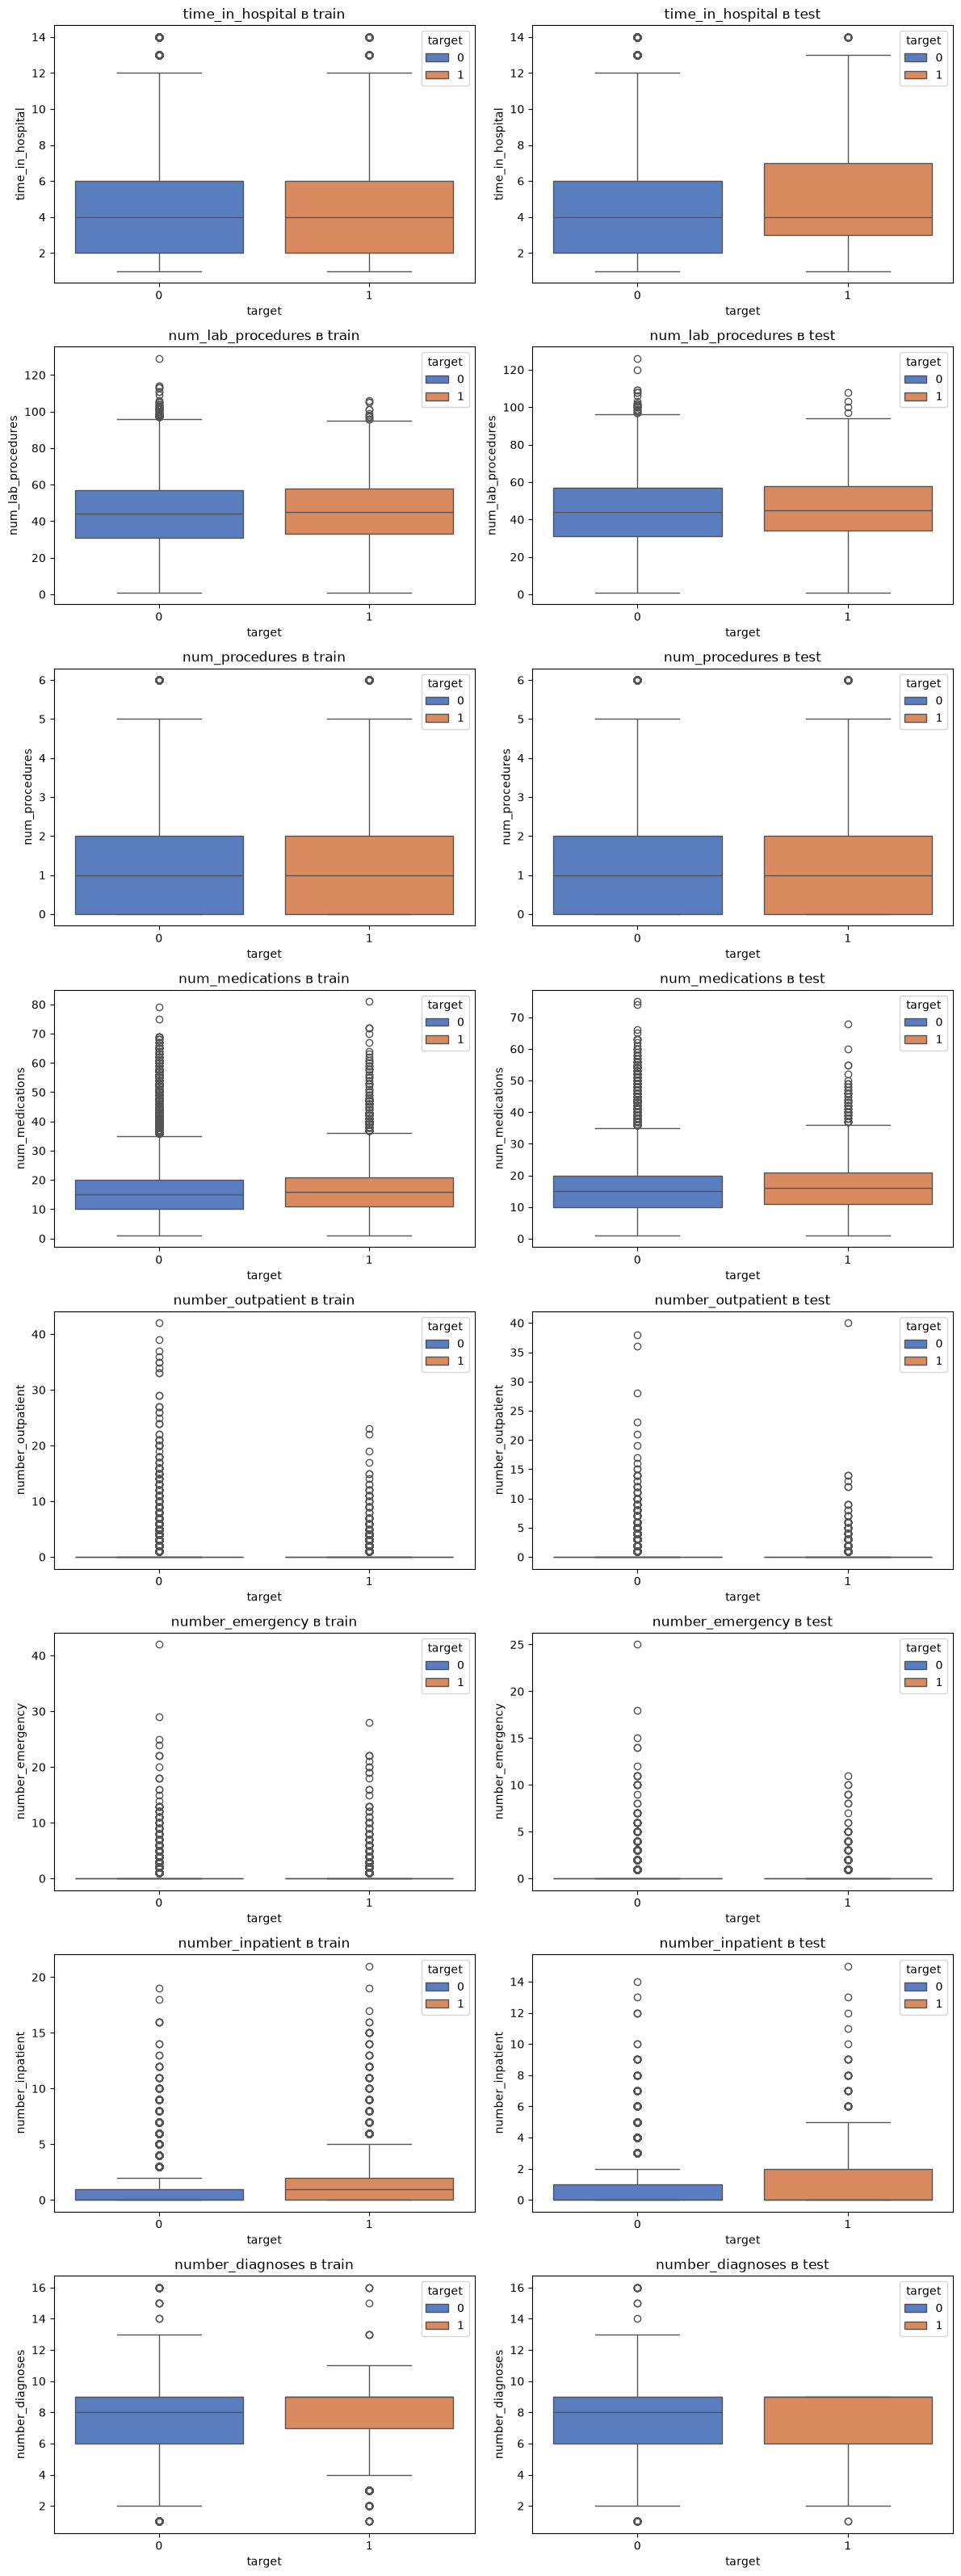

In [9]:
num_cols = [
    "time_in_hospital", "num_lab_procedures", "num_procedures", 
    "num_medications", "number_outpatient", "number_emergency", 
    "number_inpatient", "number_diagnoses",
]
n = len(num_cols)

fig, axes = plt.subplots(n, 2, figsize=(12, 4 * n))

for i, col in enumerate(num_cols):
    # train
    ax_tr = axes[i, 0]
    sns.boxplot(data=train, x=TARGET_COL, y=col, hue=TARGET_COL,
                palette=PALETTE,
                ax=ax_tr)
    ax_tr.set_title(f"{col} в train")

    # test
    ax_te = axes[i, 1]
    sns.boxplot(data=test, x=TARGET_COL, y=col, hue=TARGET_COL,
                palette=PALETTE,
                ax=ax_te)
    ax_te.set_title(f"{col} в test")

plt.tight_layout()
plt.show()

Важный вывод: `train` и `test` выглядят одинаково, значит split корректный, распределения не смещены.

Смотрим на сдвиг медианы между `target=0` и `target=1`: чем он больше, тем сильнее признак различает классы.

| Признак | Медиана класса 0 | Медиана класса  1 | Вывод |
|:---:|:---:|:---:|:---:|
| time_in_hospital | 3 | 4 | Слабый сдвиг, но есть: повторно госпитализированные лежат чуть дольше | 
| num_lab_procedures | 44 | 46 | Очень слабый сдвиг, почти не различает | 
| num_procedures | 1 | 1 | Практически нет различия, слабый признак | 
| num_medications | 13 | 15 | Заметный сдвиг: у target=1 больше лекарств | 
| number_outpatient | 0 | 0 | Медианы совпадают, но хвост у target=1 длиннее: больше редких больших значений | 
| number_emergency | 0 | 0 | То же: медианы 0, но у target=1 больше редких больших значений | 
| number_inpatient | 0 | 1 | Сильный сдвиг. У повторно госпитализированных чаще есть госпитализации в прошлом году | 
| number_diagnoses | 8 | 9 | Заметный сдвиг: больше диагнозов - выше риск | 

Удалять выбросы не нужно ни для одного признака. Это клинические данные, и выбросы - это пациенты, которые как раз и интересны модели (они чаще повторно госпитализируются).

Однако для линейных моделей (логистической регрессии) выбросы сильно меняют коэффициенты, поэтому можно применить метод клиппирования.

Клиппирование по 99-му перцентилю применено к 4 признакам. Обрезано более 500 наблюдений на каждый признак. Пороги клиппирования: num_lab_procedures - 85, num_medications - 43, number_outpatient - 5, number_emergency - 3. Признаки number_inpatient и number_diagnoses не клиппировались как несущие клинически значимый сигнал в хвосте.

In [10]:
before_data = train.copy()

In [11]:
clip_cols = ["num_lab_procedures", "num_medications",
             "number_outpatient", "number_emergency"]

thresholds = {col: train[col].quantile(0.99) for col in clip_cols}

for col in clip_cols:
    train[col] = train[col].clip(upper=thresholds[col])
    val[col] = val[col].clip(upper=thresholds[col])
    test[col] = test[col].clip(upper=thresholds[col])

for col in clip_cols:
    n = (before_data[col] > thresholds[col]).sum()
    print(f"{col}: threshold={thresholds[col]:.1f}; обрезано={n} ({n/len(before_data):.2%}); max до={before_data[col].max():.1f}; max после={train[col].max():.1f}")

num_lab_procedures: threshold=85.0; обрезано=522 (0.85%); max до=129.0; max после=85.0
num_medications: threshold=43.0; обрезано=573 (0.94%); max до=81.0; max после=43.0
number_outpatient: threshold=5.0; обрезано=568 (0.93%); max до=42.0; max после=5.0
number_emergency: threshold=3.0; обрезано=563 (0.92%); max до=42.0; max после=3.0


### Feature Engineering

1. Бинарные

Проблема: `number_outpatient`, `number_emergency`, `number_inpatient` имеют медиану 0 и длинный хвост из-за "выбросов"

In [12]:
warnings.simplefilter(action='ignore', category=pd.errors.PerformanceWarning)

In [13]:
cols = ["number_outpatient", "number_emergency", "number_inpatient"]

for col in cols:
    for df in [train, val, test]:
        df[f"{col}_bin"] = (df[col] > 0).astype(np.int8)
        df[f"{col}_bin"] = (df[col] > 0).astype(np.int8)
        df[f"{col}_bin"] = (df[col] > 0).astype(np.int8)

train[["number_outpatient", "number_outpatient_bin"]].head()

,number_outpatient,number_outpatient_bin
0,2,1
1,0,0
2,0,0
3,0,0
4,0,0


2. Суммарное количество посещений пациента

In [14]:
for df in [train, val, test]:
    df["total_visits"] = df[cols].sum(axis=1)

train[cols + ["total_visits"]].head()

,number_outpatient,number_emergency,number_inpatient,total_visits
0,2,0,1,3
1,0,0,0,0
2,0,0,0,0
3,0,0,0,0
4,0,0,0,0


3. Интенсивность лечения

Сколько лекарств/процедур в день

`time_in_hospital` варьируется 1-14, и 10 лекарств за 2 дня - это интенсивнее, чем 10 за 14 дней

In [15]:
for df in [train, val, test]:
    df["meds_per_day"] = df["num_medications"] / df["time_in_hospital"]
    df["procedures_per_day"] = df["num_procedures"] / df["time_in_hospital"]
    df["labs_per_day"] = df["num_lab_procedures"] / df["time_in_hospital"]

train[["meds_per_day", "procedures_per_day", "labs_per_day"]].head()

,meds_per_day,procedures_per_day,labs_per_day
0,6.500000,2.500000,5.500000
1,8.000000,0.500000,22.000000
2,8.000000,0.000000,51.000000
3,5.333333,2.000000,10.333333
4,2.153846,0.153846,5.230769


### Масштабирование данных

Для масштабирования количественных признаков выбран `RobustScaler`, а не `StandardScaler` или `MinMaxScaler`. Признаки `number_outpatient`, `number_emergency`, `number_inpatient` имеют сильно скошенное распределение: у более половины пациентов значение равно нулю, а у единичных пациентов могут быть значения 20 и более; `mean` и `std` (используемые `StandardScaler`) чувствительны к выбросам, а `min/max` (используемые `MinMaxScaler`) сжимают основную массу значений в узкий диапазон. RobustScaler центрирует по медиане и масштабирует по межквартильному размаху (IQR), которые устойчивы к экстремальным значениям, сохраняя информативный разброс значений. Параметры (median, IQR) рассчитаны только на обучающей выборке.

In [16]:
scaler = RobustScaler()

train[num_cols] = scaler.fit_transform(train[num_cols])
val[num_cols] = scaler.transform(val[num_cols])
test[num_cols] = scaler.transform(test[num_cols])

### Анализ мультиколлинеарности

Для выявления мультиколлинеарности построена матрица коэффициентов корреляции Пирсона по обучающей выборке. Анализировались только пары признаков, расположенные выше главной диагонали (верхний треугольник матрицы), чтобы избежать дублирования пар. 

Пары с абсолютным значением коэффициента корреляции больше заданного порога рассматривались как кандидаты на исключение. 

In [17]:
corr = train.corr()

upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pairs = upper.stack().reset_index()
pairs.columns = ["feature_1", "feature_2", "corr"]
pairs["abs_corr"] = pairs["corr"].abs()

high_corr = pairs[pairs["abs_corr"] > MAX_CORR_COEF].sort_values("abs_corr", ascending=False)
print(f"Пар с |r| > {MAX_CORR_COEF:.2f}: {len(high_corr)}")
print(high_corr.to_string(index=False))

Пар с |r| > 0.80: 5
        feature_1                 feature_2      corr  abs_corr
     a1c_measured     A1Cresult_NotMeasured -1.000000  1.000000
     glu_measured max_glu_serum_NotMeasured -1.000000  1.000000
 number_emergency      number_emergency_bin  0.883043  0.883043
 number_inpatient              total_visits  0.815950  0.815950
number_outpatient     number_outpatient_bin  0.815805  0.815805


По матрице корреляций Пирсона на `train` выявлено 5 пар с `|r| > MAX_CORR_COEF`:

- точные дубли `a1c_measured`, `glu_measured` удалены из всех наборов.
- структурные дубли `number_*_bin`, `total_visits` удалены также из-за возможных нестабильных коэффициентов у линейных моделей.

In [18]:
cols_to_drop = ["a1c_measured", "glu_measured", "number_outpatient_bin", "number_emergency_bin", "number_inpatient_bin", "total_visits"]
train = train.drop(columns=cols_to_drop)
val = val.drop(columns=cols_to_drop)
test = test.drop(columns=cols_to_drop)

### Дисбаланс классов

Целевая переменная несбалансирована: положительный класс составляет около 10% наблюдений. Для борьбы с дисбалансом будут использованы:

- class_weight="balanced" для логистической регрессии: веса классов обратно пропорциональны их частотам, что увеличивает штраф за ошибки на меньшинстве;

- scale_pos_weight для моделей градиентного бустинга: параметр, аналогично увеличивающий вес положительного класса;

- подбор порога классификации на валидационной выборке по максимуму F1-score, поскольку порог 0.5 не оптимален при дисбалансе.

SMOTE не применялся: матрица признаков содержит one-hot-колонки, для которых интерполяция (основа SMOTE) не имеет смысла. Undersampling не применялся из-за потери 80% данных нулевого класса.

Разделим на X и y

In [19]:
def x_y_selection(df, target_col):
    return df.drop(columns=[group_col, target_col]), df[target_col]

In [20]:
X_train, y_train = x_y_selection(train, TARGET_COL)
X_val, y_val = x_y_selection(val, TARGET_COL)
X_test, y_test = x_y_selection(test, TARGET_COL)

Сохраняем в pickle

In [21]:
X_train.to_pickle("../data/processed/X_train.pkl")
X_val.to_pickle("../data/processed/X_val.pkl")
X_test.to_pickle("../data/processed/X_test.pkl")

y_train.to_pickle("../data/processed/y_train.pkl")
y_val.to_pickle("../data/processed/y_val.pkl")
y_test.to_pickle("../data/processed/y_test.pkl")

train.to_pickle("../data/processed/train.pkl")